In [81]:
import pandas as pd

In [82]:
p_nom = 12e6
bar_e_0 = 0.36

In [83]:
#name = 'С-5' # 0.057
#name = 'С-8' # 0.08
#name = 'С-13' # 0.122
#name = '9М27Ф' # 0.22
#name = 'С-24' # 0.24
name = '9М55' # 0.3
#name = 'Х-15' # 0.455

In [84]:
import pandas as pd
import numpy as np

# ============================================================
# 1. Чтение базы с параметрами геометрии
# ============================================================
FILE = "database-1-2026-09-24.xlsx"
SHEET = "Лист1"
OUT_COLS = ["D_ks", "D_a", "D_kr", "e_0", "r", "l_zar"]


def load_db(path: str = FILE, sheet: str = SHEET) -> pd.DataFrame:
    return pd.read_excel(path, sheet_name=sheet, header=0)


def get_params(name: str, bar_e_0: float, p_nom: float,
               df: pd.DataFrame | None = None, tol: float = 1e-9) -> dict:
    if df is None:
        df = load_db()
    df = df.rename(columns=lambda c: str(c).strip())
    mask = (
        (df["Name"].astype(str).str.strip() == str(name).strip())
        & (df["bar_e_0"].astype(float).sub(float(bar_e_0)).abs() < tol)
        & (df["p_nom"].astype(float).sub(float(p_nom)).abs() < tol)
    )
    rows = df.loc[mask, OUT_COLS]
    if rows.empty:
        raise KeyError(f"Нет записи: Name={name!r}, bar_e_0={bar_e_0}, p_nom={p_nom}")
    if len(rows) > 1:
        raise KeyError(f"Найдено {len(rows)} совпадений — комбинация не уникальна.")
    return rows.iloc[0].to_dict()


# ============================================================
# 2. Чтение таблиц допусков (ИСПРАВЛЕНО)
# ============================================================
TOL_FILE = "Допуски.xlsx"
SHEET_TRT = "Допуски ТРТ"
SHEET_NOZ = "Допуски сопла"


def load_tolerances(path: str = TOL_FILE,
                    sheet_trt: str = SHEET_TRT,
                    sheet_nozzle: str = SHEET_NOZ):
    """
    Возвращает (df_trt, df_nozzle) — таблицы допусков с колонками min, max, value.
    Читаем с header=None и отбрасываем первые 2 строки (объединенный заголовок + строка min/max).
    """
    df_trt = pd.read_excel(path, sheet_name=sheet_trt, header=None).iloc[2:, :3]
    df_noz = pd.read_excel(path, sheet_name=sheet_nozzle, header=None).iloc[2:, :3]

    df_trt.columns = ["min", "max", "value"]
    df_noz.columns = ["min", "max", "value"]

    df_trt = df_trt.reset_index(drop=True)
    df_noz = df_noz.reset_index(drop=True)

    for df in (df_trt, df_noz):
        for col in ["min", "max", "value"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return (df_trt.dropna(subset=["min", "max", "value"]).reset_index(drop=True),
            df_noz.dropna(subset=["min", "max", "value"]).reset_index(drop=True))


def lookup_tolerance(size: float, df: pd.DataFrame) -> float:
    """
    Находит значение из таблицы по интервалу (min, max].
    """
    df = df.sort_values("min").reset_index(drop=True)
    for _, row in df.iterrows():
        if row["min"] < size <= row["max"]:
            return float(row["value"])
    if size <= df.iloc[0]["max"]:
        return float(df.iloc[0]["value"])
    raise ValueError(f"Размер {size} вне таблицы допусков "
                     f"(диапазон {df['min'].min()}..{df['max'].max()})")


# ============================================================
# 3. Назначение min/max с учётом отклонений
# ============================================================
def assign_limits(params: dict,
                  df_trt: pd.DataFrame,
                  df_noz: pd.DataFrame) -> dict:
    """
    ТРТ (D_ks, e_0, r, l_zar):
        Значение из таблицы = ПОЛЕ ДОПУСКА в ММ. Отклонение = поле / 2.
        Симметричное: ±отклонение.
    Сопло (D_a, D_kr):
        Значение из таблицы = ПОЛЕ ДОПУСКА в МКМ. Отклонение = поле / 2.
        Симметричное: ±отклонение относительно номинала.
        Поиск по номинальному диаметру сопла (D_a и D_kr соответственно).
    """
    result = {}

    # --- ТРТ ---
    for key in ("D_ks", "e_0", "r", "l_zar"):
        nom_m = float(params[key])
        nom_mm = nom_m * 1000.0
        field_mm = lookup_tolerance(nom_mm, df_trt)
        half_mm = field_mm / 2.0
        result[key] = {
            "nom": nom_m,
            "tol_mm": half_mm,
            "min": (nom_mm - half_mm) / 1000.0,
            "max": (nom_mm + half_mm) / 1000.0,
        }

    # --- Сопло ---
    for key in ("D_a", "D_kr"):
        nom_m = float(params[key])
        nom_mm = nom_m * 1000.0
        field_um = lookup_tolerance(nom_mm, df_noz)   # поиск по номиналу D_a / D_kr
        half_mm = field_um / 1000.0 / 2.0
        result[key] = {
            "nom": nom_m,
            "tol_mm": half_mm,
            "min": (nom_mm - half_mm) / 1000.0,
            "max": (nom_mm + half_mm) / 1000.0,
        }

    return result

# ============================================================
# 4. Монте-Карло
# ============================================================
N_SAMPLES = 10000
RNG = np.random.default_rng(seed=41)

def monte_carlo_geometry(limits: dict, n: int = N_SAMPLES, rng=RNG) -> pd.DataFrame:
    data = {}
    for key, v in limits.items():
        lo, hi = v["min"], v["max"]
        nom = v["nom"]
        mu = nom                       # для всех параметров μ = номинал
        sigma = (hi - lo) / 6.0
        if sigma <= 0:
            data[key] = np.full(n, mu)
            continue
        samples = rng.normal(loc=mu, scale=sigma, size=n)
        data[key] = np.clip(samples, lo, hi)
    return pd.DataFrame(data)


# ============================================================
# 5. Проверка
# ============================================================
if __name__ == "__main__":
    name = name
    bar_e_0 = bar_e_0
    p_nom = p_nom

    db = load_db()
    params = get_params(name, bar_e_0, p_nom, df=db)

    df_trt, df_noz = load_tolerances()


    limits = assign_limits(params, df_trt, df_noz)

    print(f"{name}: bar_e_0={bar_e_0}, p_nom={p_nom/1e6:.0f} МПа")
    print("Номинал (в метрах):", params)
    print("\nПредельные размеры с отклонениями:")
    print(f"{'Параметр':<8} {'Номинал(мм)':>12} {'Откл.(мм)':>11} "
          f"{'min(м)':>12} {'max(м)':>12}")
    for k, v in limits.items():
        print(f"{k:<8} {v['nom']*1000:>12.4f} {v['tol_mm']:>11.6f} "
              f"{v['min']:>12.6f} {v['max']:>12.6f}")

9М55: bar_e_0=0.36, p_nom=12 МПа
Номинал (в метрах): {'D_ks': 0.288, 'D_a': 0.2346, 'D_kr': 0.0646, 'e_0': 0.0518, 'r': 0.0084, 'l_zar': 1.3222}

Предельные размеры с отклонениями:
Параметр  Номинал(мм)   Откл.(мм)       min(м)       max(м)
D_ks         288.0000    1.000000     0.287000     0.289000
e_0           51.8000    0.600000     0.051200     0.052400
r              8.4000    0.400000     0.008000     0.008800
l_zar       1322.2000    1.400000     1.320800     1.323600
D_a          234.6000    0.036000     0.234564     0.234636
D_kr          64.6000    0.023000     0.064577     0.064623


In [85]:
import os

# Генерируем данные
df_mc = monte_carlo_geometry(limits, n=N_SAMPLES)

# Добавляем case_id
df_mc.insert(0, 'case_id', range(1, len(df_mc) + 1))

# Сохраняем в тот же файл (в МЕТРАХ)
fname = f"{name}-{bar_e_0}-{p_nom/1e6:.0f}-Разброс геометрии.xlsx"
df_mc.to_excel(fname, index=False)

print(f"✅ Перезаписано: {fname}")
print(f"   Время: {pd.Timestamp(os.path.getmtime(fname), unit='s')}")
print(f"   Строк: {len(df_mc)}")
print(f"   D_a:  μ={df_mc['D_a'].mean()*1000:.4f} мм, σ={df_mc['D_a'].std()*1000:.4f} мм")
print(f"   D_kr: μ={df_mc['D_kr'].mean()*1000:.4f} мм, σ={df_mc['D_kr'].std()*1000:.4f} мм")
print(f"   Уникальных D_a: {df_mc['D_a'].nunique()} из {len(df_mc)}")

✅ Перезаписано: 9М55-0.36-12-Разброс геометрии.xlsx
   Время: 2026-10-17 08:42:38.762009144
   Строк: 10000
   D_a:  μ=234.6000 мм, σ=0.0119 мм
   D_kr: μ=64.6000 мм, σ=0.0076 мм
   Уникальных D_a: 9981 из 10000


Загружено строк: 10000
Колонки: ['case_id', 'D_ks', 'e_0', 'r', 'l_zar', 'D_a', 'D_kr']


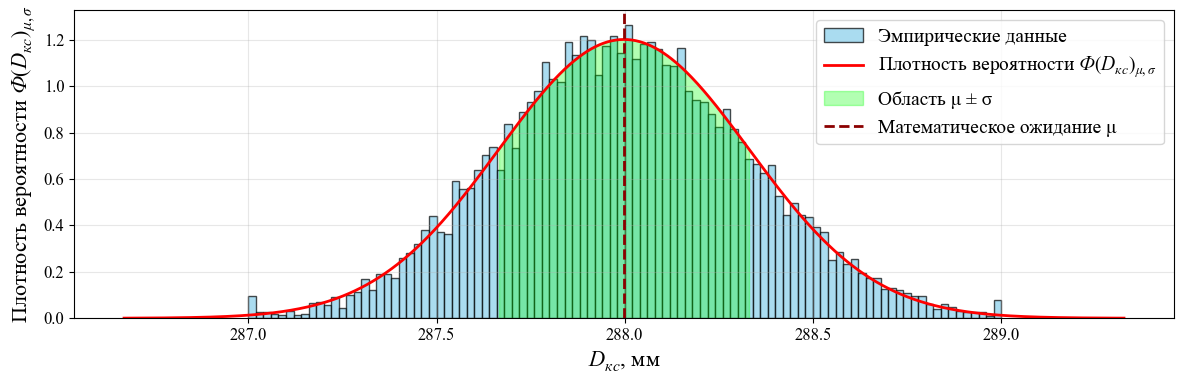

D_ks: n=10000, μ=287.998067, σ=0.332091, σ²=0.110284


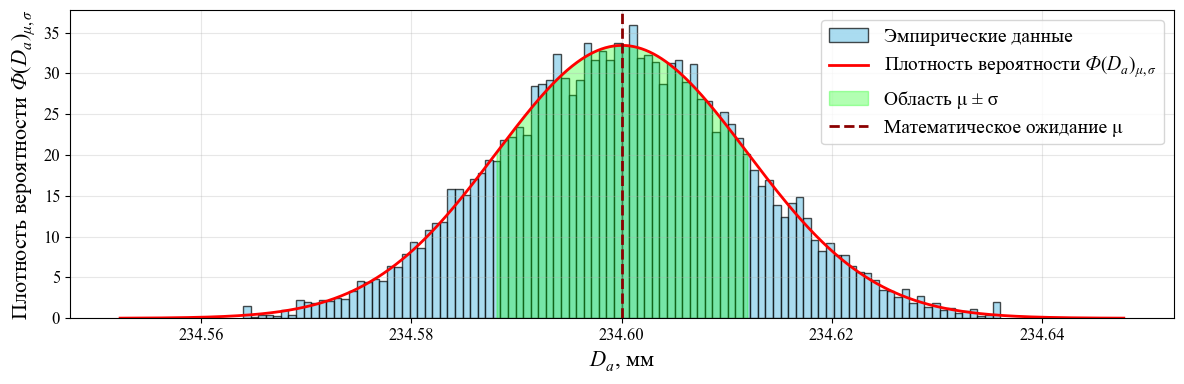

D_a: n=10000, μ=234.600035, σ=0.011933, σ²=0.000142


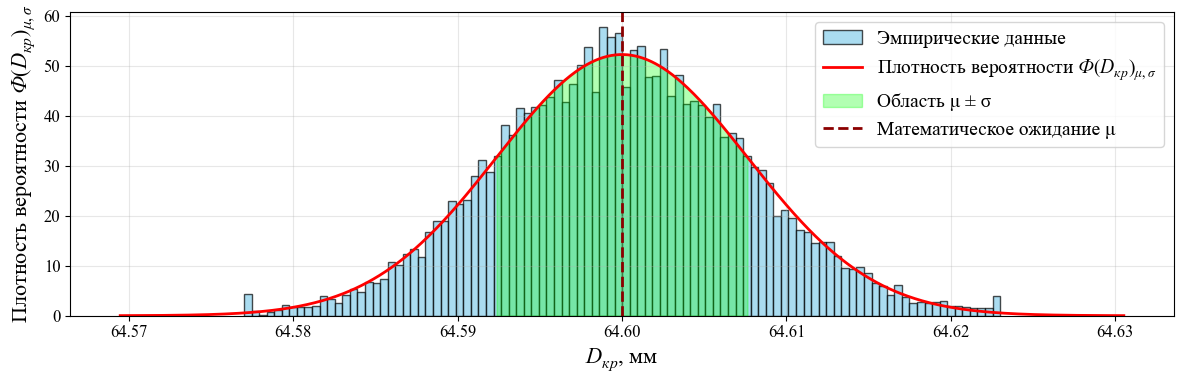

D_kr: n=10000, μ=64.599996, σ=0.007632, σ²=0.000058


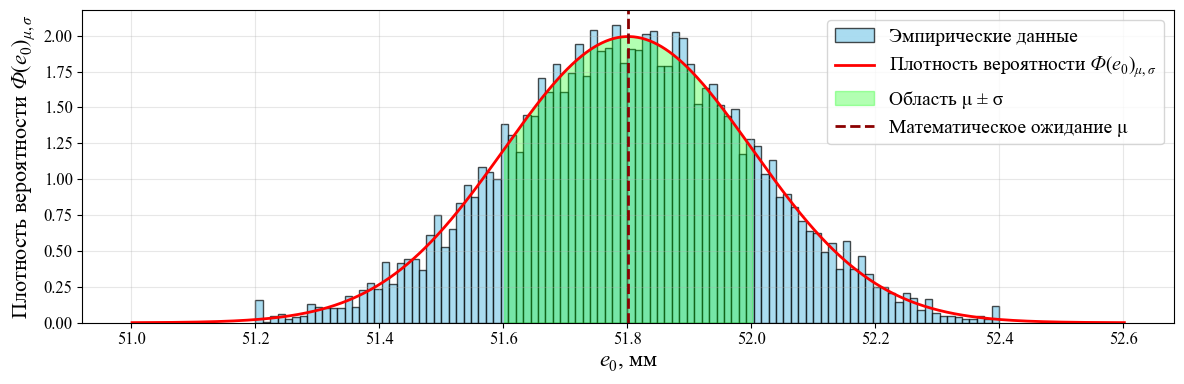

e_0: n=10000, μ=51.801546, σ=0.200087, σ²=0.040035


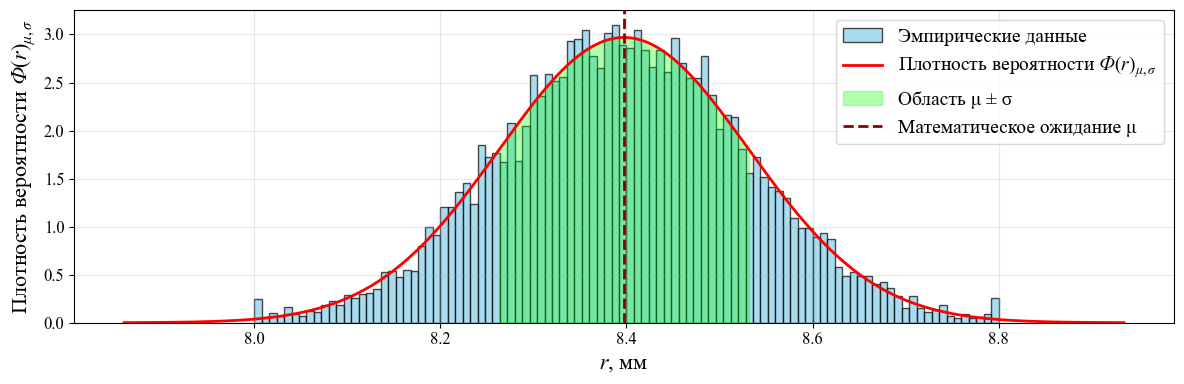

r: n=10000, μ=8.397374, σ=0.134350, σ²=0.018050


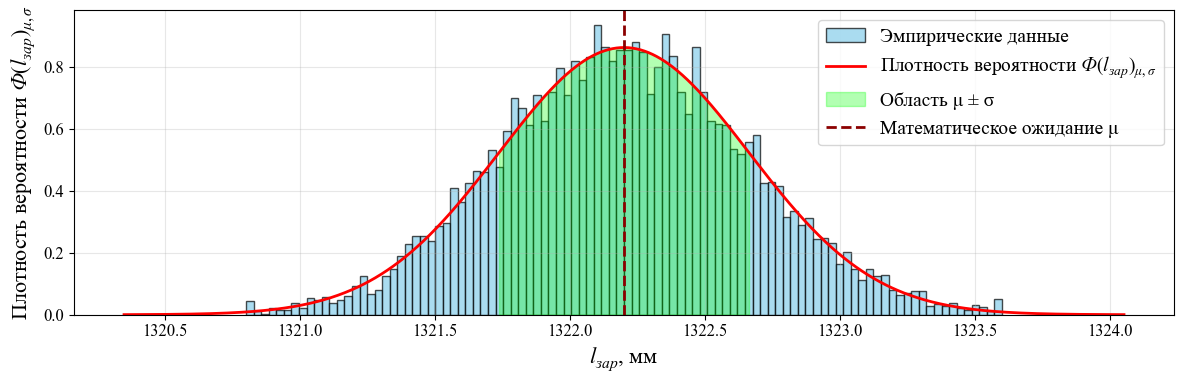

l_zar: n=10000, μ=1322.199849, σ=0.463060, σ²=0.214425

СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ (геометрия)
Параметр     n μ (мат. ожидание) σ (ср. отклонение) σ² (дисперсия)
    D_ks 10000        287.998067           0.332091   1.102842e-01
     D_a 10000        234.600035           0.011933   1.423862e-04
    D_kr 10000         64.599996           0.007632   5.824050e-05
     e_0 10000         51.801546           0.200087   4.003481e-02
       r 10000          8.397374           0.134350   1.804987e-02
   l_zar 10000       1322.199849           0.463060   2.144246e-01

Сводная таблица сохранена: Сводная_таблица_геометрии.xlsx


In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. Настройка стиля графиков
# ============================================================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'


# ============================================================
# 2. Загрузка данных разброса геометрии
# ============================================================
# Вариант A: если есть готовый файл разброса геометрии
df_all = pd.read_excel(f"{name}-{bar_e_0}-{p_nom/1e6:.0f}-Разброс геометрии.xlsx")
mm_columns = ['D_ks', 'D_a', 'D_kr', 'e_0', 'r', 'l_zar']
for col in mm_columns:
    if col in df_all.columns:
        df_all[col] = df_all[col] * 1000.0

df_all.dropna(inplace=True)

print(f"Загружено строк: {len(df_all)}")
print(f"Колонки: {list(df_all.columns)}")


# ============================================================
# 3. LaTeX-имена параметров
# ============================================================
latex_names = {
    'e_0':   r'$e_0$, мм',
    'l_zar': r'$l_{зар}$, мм',
    'r':     r'$r$, мм',
    'D_ks':  r'$D_{кс}$, мм',
    'D_a':   r'$D_{а}$, мм',
    'D_kr':  r'$D_{кр}$, мм',
}

latex_names_1 = {
    'e_0':   r'$e_0$',
    'l_zar': r'$l_{зар}$',
    'r':     r'$r$',
    'D_ks':  r'$D_{кс}$',
    'D_a':   r'$D_{а}$',
    'D_kr':  r'$D_{кр}$',
}


# ============================================================
# 4. Функция построения распределения для одного параметра
# ============================================================
def plot_distribution(data, column_name, bins=100):
    """
    Строит гистограмму и накладывает кривую нормального распределения
    для одной колонки DataFrame.
    """
    values = data[column_name].dropna().values
    display_name   = latex_names.get(column_name, column_name)
    display_name_1 = latex_names_1.get(column_name, column_name)

    n        = len(values)
    mean_val = np.mean(values)
    std_val  = np.std(values, ddof=1)
    variance = std_val ** 2

    fig, ax = plt.subplots(figsize=(12, 4))

    # Гистограмма
    ax.hist(values, bins=bins, density=True, alpha=0.7,
            color='skyblue', edgecolor='black', label='Эмпирические данные')

    # Кривая нормального распределения
    x = np.linspace(mean_val - 4 * std_val, mean_val + 4 * std_val, 1000)
    y = stats.norm.pdf(x, mean_val, std_val)
    clean_name_1 = display_name_1.replace('$', '')
    ax.plot(x, y, 'r-', linewidth=2,
            label=fr'Плотность вероятности $Ф({clean_name_1})_{{\mu,\sigma}}$')

    # Область μ ± σ
    x_fill = np.linspace(mean_val - std_val, mean_val + std_val, 1000)
    y_fill = stats.norm.pdf(x_fill, mean_val, std_val)
    ax.fill_between(x_fill, y_fill, alpha=0.3, color='lime', label='Область μ ± σ')

    # Математическое ожидание
    ax.axvline(mean_val, color='darkred', linestyle='--', linewidth=2,
               label='Математическое ожидание μ')

    ax.set_xlabel(display_name, fontsize=16)
    ax.set_ylabel(fr'Плотность вероятности $Ф({clean_name_1})_{{\mu,\sigma}}$',
                  fontsize=16)
    ax.legend(loc='best', fontsize=14)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'Distribution_{column_name}.png', dpi=150)
    plt.show()

    return {
        'column':   column_name,
        'n':        n,
        'mean':     mean_val,
        'std':      std_val,
        'variance': variance,
    }


# ============================================================
# 5. Построение ТОЛЬКО для нужных параметров
# ============================================================
geom_columns = ['D_ks', 'D_a', 'D_kr', 'e_0', 'r', 'l_zar']

results = {}
for col in geom_columns:
    if col in df_all.columns:
        stats_dict = plot_distribution(df_all, col, bins=100)
        results[col] = stats_dict
        print(f"{col}: n={stats_dict['n']}, "
              f"μ={stats_dict['mean']:.6f}, "
              f"σ={stats_dict['std']:.6f}, "
              f"σ²={stats_dict['variance']:.6f}")
    else:
        print(f"⚠️ Колонка {col} отсутствует в df_all — пропускаю")


# ============================================================
# 6. Сводная таблица результатов
# ============================================================
print("\n" + "=" * 80)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ (геометрия)")
print("=" * 80)

summary_data = []
for col, stat in results.items():
    summary_data.append({
        'Параметр':          col,
        'n':                 stat['n'],
        'μ (мат. ожидание)': f"{stat['mean']:.6f}",
        'σ (ср. отклонение)': f"{stat['std']:.6f}",
        'σ² (дисперсия)':     f"{stat['variance']:.6e}",
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Сохранение сводной таблицы
summary_df.to_excel('Сводная_таблица_геометрии.xlsx', index=False)
print("\nСводная таблица сохранена: Сводная_таблица_геометрии.xlsx")

In [87]:
import os
fname = f"{name}-{bar_e_0}-{p_nom/1e6:.0f}-Разброс геометрии.xlsx"
print("Файл существует:", os.path.exists(fname))
print("Путь:", os.path.abspath(fname))
print("Изменён:", pd.Timestamp(os.path.getmtime(fname), unit='s') if os.path.exists(fname) else "—")

Файл существует: True
Путь: c:\Users\Андрей\Desktop\НИРС\Программы\Разброс\Original\Разброс геометрии\9М55-0.36-12-Разброс геометрии.xlsx
Изменён: 2026-10-17 08:42:38.762009144


In [88]:
import os

# Генерируем данные
df_mc = monte_carlo_geometry(limits, n=N_SAMPLES)

# Добавляем case_id
df_mc.insert(0, 'case_id', range(1, len(df_mc) + 1))

# Сохраняем в тот же файл (в МЕТРАХ)
fname = f"{name}-{bar_e_0}-{p_nom/1e6:.0f}-Разброс геометрии.xlsx"
df_mc.to_excel(fname, index=False)

print(f"✅ Перезаписано: {fname}")
print(f"   Время: {pd.Timestamp(os.path.getmtime(fname), unit='s')}")
print(f"   Строк: {len(df_mc)}")
print(f"   D_a:  μ={df_mc['D_a'].mean()*1000:.4f} мм, σ={df_mc['D_a'].std()*1000:.4f} мм")
print(f"   D_kr: μ={df_mc['D_kr'].mean()*1000:.4f} мм, σ={df_mc['D_kr'].std()*1000:.4f} мм")
print(f"   Уникальных D_a: {df_mc['D_a'].nunique()} из {len(df_mc)}")

✅ Перезаписано: 9М55-0.36-12-Разброс геометрии.xlsx
   Время: 2026-10-17 08:42:44.219554186
   Строк: 10000
   D_a:  μ=234.5999 мм, σ=0.0120 мм
   D_kr: μ=64.6001 мм, σ=0.0076 мм
   Уникальных D_a: 9977 из 10000
